# The Silent Group: open track, forgery forensics
*Qiskit Fall Fest 2026, Track 2. Aditi Kamal*

The scored solver answers one question per meeting: the secret, or `none` if a broadcast is forged. This extension asks a bigger one: **what does a sealed group still give away?**

For every forged broadcast X we find, using only the device:
- the smallest q such that X^q is a power of g, and the exact relation X^q = g^w, **verified on the device**;
- the structure of the group ⟨g, X⟩ ≅ ℤ_d1 × ℤ_d2;
- a split X = g^c · y into a genuine-looking part and a small “tag” y with y^q = e;
- how several forged tags relate to each other (one fake reused, or independent fakes);
- facts about the hidden group G itself, and the keys the honest parties still share.

**Headline results**
- **public_2:** B is forged with tag order q = 585,585 = 3² · 5 · 7 · 11 · 13². The hidden group is **provably non-cyclic** with |G| ≥ 2.18 × 10¹⁶ (≈ 2^54.3). The Alice–Charlie pair key is recovered, and a message encrypted under it is decrypted.
- **Ground truth:** on mock groups with known structure, the method recovers the true structure exactly, including the *entire* hidden group ℤ_6145295 × ℤ_53838929495 from one forged broadcast.
- **public_1 (control):** all three exponents, all pair keys and the full secret 5690673157912707 match the known answer.

### How to run
Start Jupyter from the `open-track/` folder with the project's virtual environment. Extra packages: `matplotlib`, `pylatexenc`, `plotly`, `nbformat`. Use **Restart & Run All**: later cells reuse results from earlier ones.

Every demo below is **live**: it queries the simulator (or simulates a circuit) when the cell runs. Forensics runs without a query budget, since it is analysis, not the scored solver (`my-silent-group/submission.py`). The forensics cells take a few minutes each.

In [1]:
import sys, importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from silentgroup import MockGroup, Oracle, load_public

SOLVER = '../my-silent-group/submission.py'
FORENSICS = '../my-silent-group/forensics'
sys.argv = ['notebook', SOLVER]          # forensics.py reads the solver path from argv

def load(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

def show(qc):
    try:
        display(qc.draw('mpl', fold=-1))
    except Exception as e:
        print(f'(mpl drawer unavailable: {e}; text version)')
        print(qc.draw('text', fold=-1))

def forged_mock(M=31, forged='C'):
    # a small mock group Z_M x Z_M where the chosen broadcast is forged
    for seed in range(50):
        try:
            return MockGroup([M, M], seed=seed, forged=forged), seed
        except ValueError:
            continue
    raise RuntimeError('could not build a forged mock')

def fresh_shots(mock, shots, M, bits=14):
    # live shots: chi(g), chi(A), chi(C) from the same character, rounded to the 1/M grid
    orc = Oracle(mock, noise=0)
    names = ['g', 'A', 'C']
    qc = S.ipe_circuit(names, bits)
    pts = []
    for _ in range(shots):
        ph = S.read_phases(orc.run(qc, shots=1), names, bits)
        pts.append({k: round(v * M) % M for k, v in ph.items()})
    return pts

R_RING, R_TUBE = 2.0, 0.8
def embed(u, v):
    # (u, v) in [0,1)^2 -> point on a torus: u around the ring, v around the tube
    th, phi = 2 * np.pi * np.asarray(u, float), 2 * np.pi * np.asarray(v, float)
    return ((R_RING + R_TUBE * np.cos(phi)) * np.cos(th),
            (R_RING + R_TUBE * np.cos(phi)) * np.sin(th),
            R_TUBE * np.sin(phi))

def knot_exponent(pts, X, M):
    # exponent read off the first shot with chi(g) != 0, as the representative with fewest windings
    for p in pts:
        if p['g']:
            a = p[X] * pow(p['g'], -1, M) % M
            return a - M if a > M // 2 else a
    return 0

S = load('solver', SOLVER)
S.VERBOSE = False
F = load('forensics', f'{FORENSICS}/forensics.py')
print('loaded solver and forensics')

loaded solver and forensics


## 1. The idea in one picture

Each shot, the device samples one random **character** χ of the hidden group: a rule that turns every element h into a fraction of a turn χ(h), with χ(gh) = χ(g) + χ(h) mod 1. Every oracle gate in that shot becomes a phase rotation by χ(h), which phase estimation can read.

If X = g^a is genuine, then **χ(X) = a · χ(g) mod 1 for every character**. A pair of phases (χ(g), χ(X)) is a point on a torus (each phase wraps around at 1), so:
- **genuine:** all points lie on one curve, a (1, a) torus knot;
- **forged:** X adds a direction that g doesn't have, and the points spread over the surface.

The cell below takes 300 fresh shots on a small noise-free mock group ℤ₃₁ × ℤ₃₁ (where the structure is visible to the eye) and draws them.

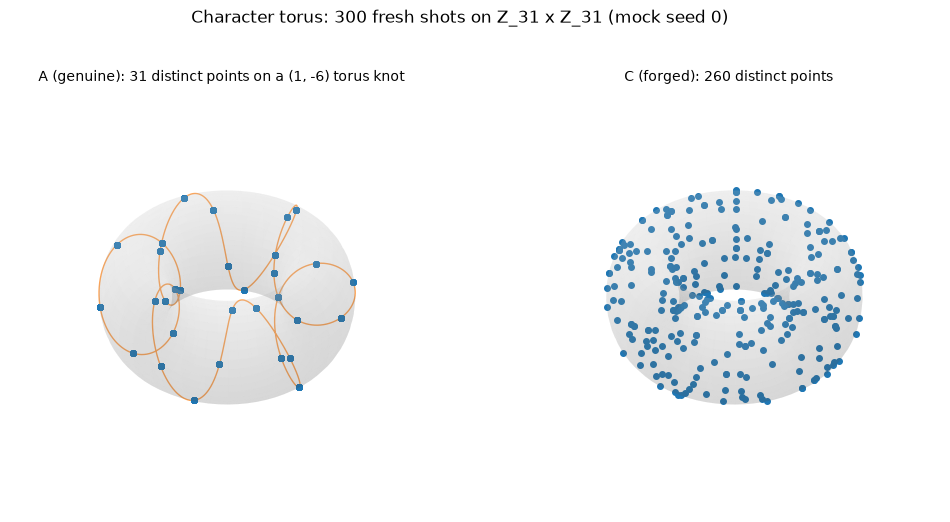

In [2]:
def live_torus(M=31, shots=300):
    mock, seed = forged_mock(M)
    pts = fresh_shots(mock, shots, M)
    U, V = np.meshgrid(np.linspace(0, 1, 72), np.linspace(0, 1, 36))
    t = np.linspace(0, 1, 4000)
    fig = plt.figure(figsize=(12, 6))
    for i, (X, label) in enumerate([('A', 'genuine'), ('C', 'forged')]):
        ax = fig.add_subplot(1, 2, i + 1, projection='3d')
        ax.plot_surface(*embed(U, V), color='lightgray', alpha=0.12, linewidth=0)
        grid = {(p['g'], p[X]) for p in pts}
        title = f'{X} ({label}): {len(grid)} distinct points'
        if X == 'A':
            a = knot_exponent(pts, 'A', M)
            ax.plot(*embed(t, (a * t) % 1), color='tab:orange', lw=1, alpha=0.7)
            title += f' on a (1, {a}) torus knot'
        ax.scatter(*embed([p['g'] / M for p in pts], [p[X] / M for p in pts]), s=16, depthshade=False)
        ax.set_title(title, fontsize=10)
        ax.set_box_aspect((1, 1, 0.45))
        ax.set_axis_off()
        ax.view_init(38, 30)
    fig.suptitle(f'Character torus: {shots} fresh shots on Z_{M} x Z_{M} (mock seed {seed})')
    plt.show()

live_torus()

**Catching a forger shot by shot.** Both panels draw the knot predicted from the first shot. Press **Play**: fresh shots arrive two at a time, green if they land on the prediction, red if they miss. The genuine broadcast stays green; the forgery turns red almost immediately. Drag either torus to rotate it.

*(Interactive plotly figures need a running notebook. `torus_emerge.gif` in this folder is a recorded version for anyone viewing the notebook without a kernel.)*

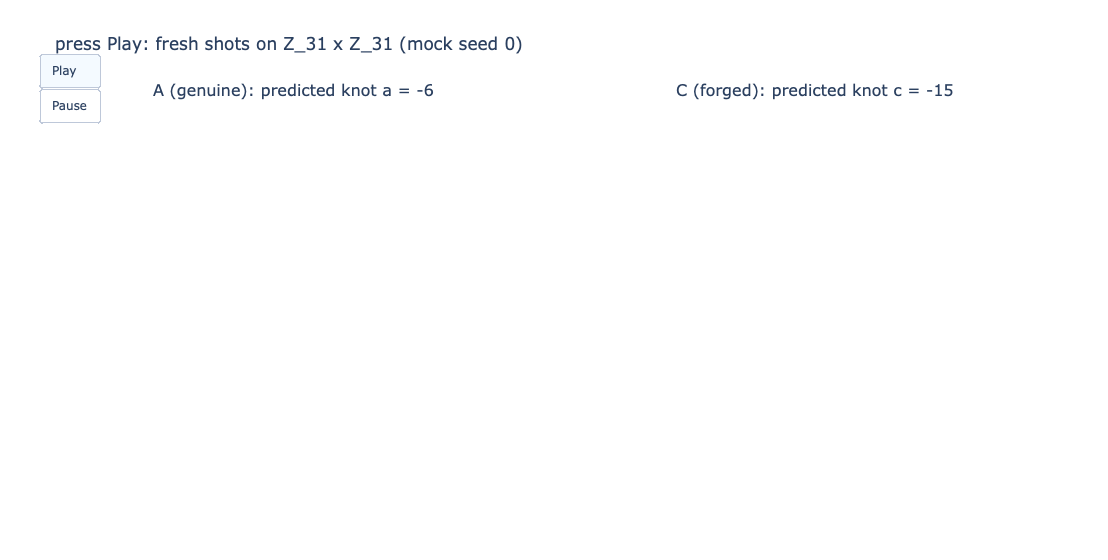

In [3]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def live_torus_emerge(M=31, shots=120, per_frame=2):
    mock, seed = forged_mock(M)
    pts = fresh_shots(mock, shots, M)
    expo = {X: knot_exponent(pts, X, M) for X in ('A', 'C')}
    U, V = np.meshgrid(np.linspace(0, 1, 60), np.linspace(0, 1, 30))
    t = np.linspace(0, 1, 3000)
    fig = make_subplots(rows=1, cols=2, specs=[[{'type': 'scene'}, {'type': 'scene'}]],
                        subplot_titles=('A (genuine): predicted knot a = ' + str(expo['A']),
                                        'C (forged): predicted knot c = ' + str(expo['C'])))
    for j, X in enumerate(('A', 'C')):
        sx, sy, sz = embed(U, V)
        fig.add_trace(go.Surface(x=sx, y=sy, z=sz, opacity=0.15, showscale=False,
                                 colorscale=[[0, 'lightgray'], [1, 'lightgray']], hoverinfo='skip'),
                      row=1, col=j + 1)
        kx, ky, kz = embed(t, (expo[X] * t) % 1)
        fig.add_trace(go.Scatter3d(x=kx, y=ky, z=kz, mode='lines', hoverinfo='skip',
                                   line=dict(color='orange', width=3), showlegend=False),
                      row=1, col=j + 1)
        fig.add_trace(go.Scatter3d(x=[], y=[], z=[], mode='markers', showlegend=False,
                                   marker=dict(size=4)), row=1, col=j + 1)

    frames = []
    for k in range(per_frame, shots + 1, per_frame):
        data, counts = [], []
        for X in ('A', 'C'):
            sub = pts[:k]
            on = [(p[X] - expo[X] * p['g']) % M == 0 for p in sub]
            x, y, z = embed([p['g'] / M for p in sub], [p[X] / M for p in sub])
            data.append(go.Scatter3d(x=x, y=y, z=z, mode='markers',
                                     marker=dict(size=4, color=['green' if o else 'red' for o in on])))
            counts.append(sum(on))
        frames.append(go.Frame(data=data, traces=[2, 5], name=str(k),
                               layout=dict(title_text=f'shots {k}:   A on the knot {counts[0]}/{k}'
                                                      f'   |   C on the knot {counts[1]}/{k}')))
    fig.frames = frames

    hidden = dict(visible=False)
    for scene in ('scene', 'scene2'):
        fig.layout[scene].update(xaxis=hidden, yaxis=hidden, zaxis=hidden,
                                 aspectmode='manual', aspectratio=dict(x=1, y=1, z=0.45))
    fig.update_layout(
        height=560, title_text=f'press Play: fresh shots on Z_{M} x Z_{M} (mock seed {seed})',
        updatemenus=[dict(type='buttons', x=0.02, y=1.12, buttons=[
            dict(label='Play', method='animate',
                 args=[None, dict(frame=dict(duration=90, redraw=True), fromcurrent=True)]),
            dict(label='Pause', method='animate',
                 args=[[None], dict(frame=dict(duration=0, redraw=False), mode='immediate')])])])
    fig.show()      # if nothing appears, try fig.show(renderer='notebook')

live_torus_emerge()

## 2. Under the hood: the circuits

### The solver's readout circuit
One control qubit does everything. For each bit, from the largest power down: reset, H, the oracle gate g^(2^(k−1)) (the box), phase corrections controlled by the bits already measured (`if_test`), H, measure. This is iterative phase estimation, the semiclassical Fourier transform of Griffiths and Niu, and it reads any number of bits of χ(g) within one shot.

Below: the real `ipe_circuit` at 4 bits, run live on a small mock group where g has order 16, so every phase is an exact 4-bit fraction.

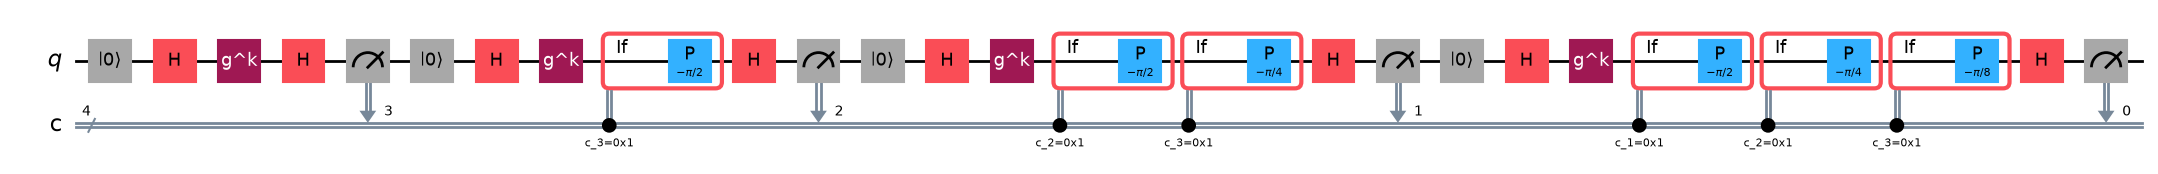

shot 0: chi(g) = 5/8   denominator 8
shot 1: chi(g) = 1/4   denominator 4
shot 2: chi(g) = 1/16   denominator 16
shot 3: chi(g) = 5/16   denominator 16
shot 4: chi(g) = 1/8   denominator 8
ord(g) = 16: each shot shows a divisor of it (one random character); the lcm over shots gives 16


In [4]:
demo = MockGroup([16], g=[3], seed=0)
demo_oracle = Oracle(demo, noise=0)
qc = S.ipe_circuit(['g'], 4)
show(qc)
for shot in range(5):
    phi = S.read_phases(demo_oracle.run(qc, shots=1), ['g'], 4)['g']
    print(f'shot {shot}: chi(g) = {phi}   denominator {phi.denominator}')
print('ord(g) = 16: each shot shows a divisor of it (one random character); the lcm over shots gives 16')

**The verification circuit.** To check a candidate exponent, both oracle gates act on the same control qubit: X^1 and g^(−a). The total rotation is χ(X) − a · χ(g), which is zero for every character exactly when X = g^a, so a correct candidate always measures 0.

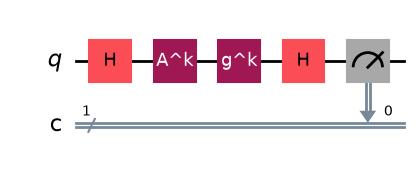

In [5]:
show(S.identity_test_circuit([('A', 1), ('g', -12345)]))

### The same circuit is an optical interferometer
In **dual-rail encoding**, one photon in two paths is two qubits: |10⟩ means the photon is in the upper arm, |01⟩ in the lower arm. A 50:50 beam splitter is an `XXPlusYYGate(π/2)`, a phase shifter is a phase gate on one arm, and the detectors measure which arm the photon leaves by. That is a **Mach–Zehnder interferometer**.

The solver's control qubit does H, phase, H. Simulating both exactly gives the **same interference curve**, sin²(φ/2). Phase kickback is interferometry, and the solver's feed-forward corrections are the adaptive feedback of single-photon phase estimation (Higgins et al., Nature 2007).

Mach-Zehnder interferometer (dual rail):


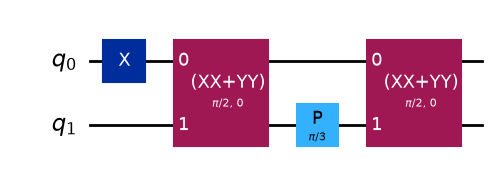

Solver control qubit:


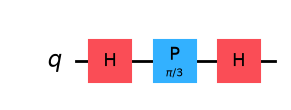

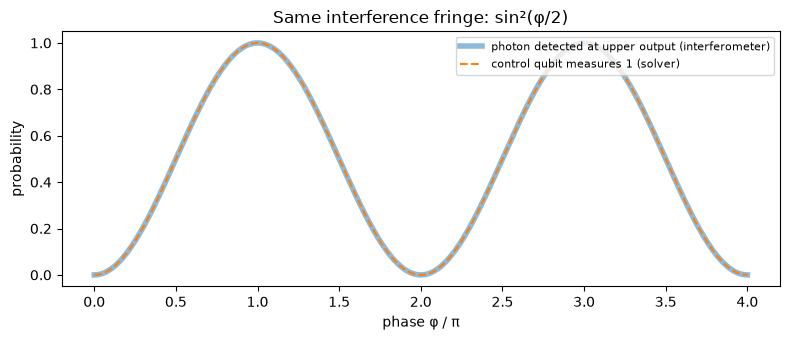

largest difference between the curves: 5.551115123125783e-16


In [6]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import XXPlusYYGate
from qiskit.quantum_info import Statevector

def mach_zehnder(phi):
    # dual-rail photon: qubit 0 = upper arm, qubit 1 = lower arm
    qc = QuantumCircuit(2)
    qc.x(0)                                       # photon enters the upper arm
    qc.append(XXPlusYYGate(np.pi / 2), [0, 1])    # 50:50 beam splitter
    qc.p(phi, 1)                                  # phase shifter in the lower arm
    qc.append(XXPlusYYGate(np.pi / 2), [0, 1])    # second beam splitter
    return qc

def kickback(phi):
    # the solver's control qubit: H, phase (from the oracle), H
    qc = QuantumCircuit(1)
    qc.h(0)
    qc.p(phi, 0)
    qc.h(0)
    return qc

print('Mach-Zehnder interferometer (dual rail):')
show(mach_zehnder(np.pi / 3))
print('Solver control qubit:')
show(kickback(np.pi / 3))

phis = np.linspace(0, 4 * np.pi, 300)
mz = [Statevector(mach_zehnder(p)).probabilities([0])[1] for p in phis]   # photon exits upper port
kb = [Statevector(kickback(p)).probabilities([0])[1] for p in phis]       # control qubit reads 1
plt.figure(figsize=(8, 3.5))
plt.plot(phis / np.pi, mz, lw=4, alpha=0.5, label='photon detected at upper output (interferometer)')
plt.plot(phis / np.pi, kb, '--', lw=1.5, label='control qubit measures 1 (solver)')
plt.xlabel('phase φ / π')
plt.ylabel('probability')
plt.title('Same interference fringe: sin²(φ/2)')
plt.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()
print('largest difference between the curves:', max(abs(a - b) for a, b in zip(mz, kb)))

## 3. Forensics: the method

For a broadcast X that the solver flagged as forged:

1. **Orders.** n = ord(g) and ord(X), with the solver's own order finder (iterative phase estimation, continued fractions, device tests).
2. **Joint readings.** Shots read χ(g) and χ(X) together, so both use the same character. Both phases are multiples of 1/D with D = lcm(n, ord X), so we round each to the 1/D grid: x_g, x_X.
3. **Smallest relation.** For each divisor q of ord(X), in increasing order, solve q · x_X ≡ w · x_g (mod D) in every shot and merge the shots with the Chinese remainder theorem (one junk shot is tolerated). The first q whose w passes the device test X^q · g^(−w) = e is the smallest. Its relation is verified, not inferred.
4. **Structure.** The relations g^n = e and X^q = g^w generate all relations between g and X, so the Smith normal form of [[n, 0], [−w, q]] gives ⟨g, X⟩ ≅ ℤ_d1 × ℤ_d2 with d1 = gcd(n, w, q) and d2 = nq / d1.
5. **Split.** X = g^c · y with y^q = e exists exactly when gcd(q, n) divides w; then q · c ≡ w (mod n).
6. **Several forgeries.** χ(A^i B^j) = i · χ(A) + j · χ(B), so combined elements are tested *classically* from the same joint shots, and only promising ones on the device. That gives the tag group Q = ⟨g, A, B, C⟩ / ⟨g⟩.

The next cell runs the full analysis live on public_2 (a few minutes).

In [7]:
summary_p2 = F.investigate('public_2', load_public('public_2'))


=== public_2 ===
ord(g) = n = 37199287125
  A = g^27142984859   (genuine, verified on device)
  B: FORGED (not a power of g)
     ord(B) = 1771394625
     smallest q with B^q in <g>: q = 585585;  verified B^585585 = g^13846742910
     [<g,B> : <g>] = 585585;   <g,B> = Z_585585 x Z_37199287125  (order 21783344551093125)
     split: B = g^23646 * y  with  y^585585 = e   (c defined mod 63525)
  C = g^23212474064   (genuine, verified on device)
  about the hidden group G:
     |G| >= |<g,A,B,C>| = n * |Q| = 21783344551093125  (~2^54.3)
     G is NOT cyclic: <g,B> = Z_585585 x Z_37199287125 with gcd 585585 > 1, and every subgroup of a cyclic group is cyclic
  partial key recovery:
     pair key g^(ac) = g^23054424601   device check A^c = g^(ac): OK
  (queries used for this analysis: 60539)


## 4. What public_2 gives away

From our runs (the cell above reproduces them; `forensics.py --repeat K` checks that every number is identical across independent runs):

- **B is forged**, and far from ⟨g⟩: the smallest power that brings it back is q = 585,585 = 3² · 5 · 7 · 11 · 13², with B^585585 = g^13846742910 verified on the device.
- ⟨g, B⟩ ≅ ℤ_585585 × ℤ_37199287125. The numbers are internally consistent: 37199287125 = 585585 × 63525.
- **The hidden group is not cyclic.** ⟨g, B⟩ has two invariant factors with gcd 585585 > 1, and every subgroup of a cyclic group is cyclic. This is a proof from verified relations, not a guess.
- **|G| ≥ |⟨g, A, B, C⟩| = 21,783,344,551,093,125 ≈ 2^54.3.** The challenge never reveals the group's size.
- **Anatomy of the forgery:** B = g^23646 · y with y^585585 = e (c is defined mod 63525). A genuine-looking power of g, times a tag.

## 5. Ground truth: mock groups with known structure

On mock groups we know the full group G, so we can check the answers. In the ~2^58 mock, one forged broadcast reveals the **entire** hidden group. In the ℤ_2^20 × ℤ_6 mock, two broadcasts are forged, and the tag group shows whether the forger reused one fake or used two.

In [8]:
mock_summaries = []
for label, make, moduli in F.CASES[1:3]:
    mock_summaries.append((label, F.investigate(label, make(), moduli)))


=== mock Z_2^20 x Z_6, forged AB ===
ord(g) = n = 1572864
(ground truth: G = Z_2 x Z_3145728)
  A: FORGED (not a power of g)
     ord(A) = 32768
     smallest q with A^q in <g>: q = 2;  verified A^2 = g^999648
     [<g,A> : <g>] = 2;   <g,A> = Z_2 x Z_1572864  (order 3145728)
     fits inside G = Z_2 x Z_3145728: yes
     split: A = g^499824 * y  with  y^2 = e   (c defined mod 786432)
  B: FORGED (not a power of g)
     ord(B) = 262144
     smallest q with B^q in <g>: q = 2;  verified B^2 = g^900756
     [<g,B> : <g>] = 2;   <g,B> = Z_2 x Z_1572864  (order 3145728)
     fits inside G = Z_2 x Z_3145728: yes
     split: B = g^450378 * y  with  y^2 = e   (c defined mod 786432)
  C = g^247294   (genuine, verified on device)
  tag group Q = <g,A,B>/<g>:
     |Q| = 2, cyclic; product of tag orders = 4
     verified relation: A * B = g^163770   (in <g>: tags cancel)
  about the hidden group G:
     |G| >= |<g,A,B,C>| = n * |Q| = 3145728  (~2^21.6)
     G is NOT cyclic: <g,A> = Z_2 x Z_157286

## 6. Partial key recovery: forging one broadcast doesn't protect the others

In public_2 there is no three-party key, but A and C are genuine, so they still share the pair key g^(ac). We encrypted a message under a key derived from that pair key (SHA-256 keystream plus an HMAC tag; only the ciphertext is stored, in `message.enc`). The cell below recovers a and c **from scratch on the device** and decrypts it. A wrong key is rejected, not turned into garbage.

*Honest caveat:* the honest parties are simulated with the pair-key exponent from an earlier run, since nobody gave us the real key. What the cell proves is that a fresh, independent device run recovers that same key from a forged meeting.

In [9]:
!{sys.executable} {FORENSICS}/decrypt.py {SOLVER}

intercepted ciphertext: 6a58fb005c514c6e7284bd690b14adeaca689559352e1b52...
recovering the broadcasts of public_2 from scratch on the device:
  A = g^27142984859   (genuine, verified)
  B: forged -> no three-party key exists
  C = g^23212474064   (genuine, verified)
pair key exponent ac mod n = 23054424601
decrypted: "The path of illumination begins at the Pantheon. Bernini's seal is false."
same ciphertext, wrong key: 'rejected (tag mismatch)'
(queries used: 59111)


## 7. Forger fingerprints

Each forgery's tag order q as a barcode in the terminal: one coloured block per prime factor, one character per bit (exponent × log₂ p). Each prime keeps one colour across all forgeries, so equal fingerprints stand out. The thin bar underneath shows ord(X).

In [10]:
!{sys.executable} {FORENSICS}/fingerprint.py {SOLVER}

saved fingerprint.png
  public_2: B: q = 3^2 * 5 * 7 * 11 * 13^2
  mock Z_2^20 x Z_6: A: q = 2
  mock Z_2^20 x Z_6: B: q = 2
  mock ~2^58: C: q = 5 * 13 * 94543

public_2: B              q      3^25  7  11  13^2 
                         ord(X) 3^2  5^3   7    11^3     13^2 

mock Z_2^20 x Z_6: A     q      2
                         ord(X)       2^15     

mock Z_2^20 x Z_6: B     q      2
                         ord(X)        2^18       

mock ~2^58: C            q      5  13       94543      
                         ord(X) 5  13      8761          94543      



## 8. Be the forger

Build a meeting with a forgery of your choice, then let forensics investigate it. Forgeries need a non-cyclic group (two moduli sharing a factor). Small groups run fastest. Your meeting also gets a case file in the next section.

In [11]:
def be_the_forger(moduli=(81, 405), forged='B', seed=1):
    # forge broadcasts in a mock group G = Z_m1 x Z_m2, then investigate the meeting
    try:
        mock = MockGroup(list(moduli), seed=seed, forged=forged)
    except ValueError as e:
        print('Cannot forge that here:', e, '(try moduli sharing a factor, or another seed)')
        return None
    print('You forged:', forged, '| true answer:', mock.answer)
    label = f'your meeting: G = Z_{moduli[0]} x Z_{moduli[1]}, forged {forged}, seed {seed}'
    return label, F.investigate(label, mock, tuple(moduli))

my_case = be_the_forger(moduli=(81, 405), forged='B', seed=1)

You forged: B | true answer: {'order': 405, 'secret': 'none'}

=== your meeting: G = Z_81 x Z_405, forged B, seed 1 ===
ord(g) = n = 405
(ground truth: G = Z_81 x Z_405)
  A = g^392   (genuine, verified on device)
  B: FORGED (not a power of g)
     ord(B) = 405
     smallest q with B^q in <g>: q = 81;  verified B^81 = g^81
     [<g,B> : <g>] = 81;   <g,B> = Z_81 x Z_405  (order 32805)
     fits inside G = Z_81 x Z_405: yes
     split: B = g^1 * y  with  y^81 = e   (c defined mod 5)
  C = g^131   (genuine, verified on device)
  about the hidden group G:
     |G| >= |<g,A,B,C>| = n * |Q| = 32805  (~2^15.0)
     G is NOT cyclic: <g,B> = Z_81 x Z_405 with gcd 81 > 1, and every subgroup of a cyclic group is cyclic
  partial key recovery:
     pair key g^(ac) = g^322   device check A^c = g^(ac): OK
  (queries used for this analysis: 26613)


## 9. Case files

One dossier per meeting, built live from the forensics results above (public_2, both mock groups, and your forged meeting). The cell also saves them as `casefiles.html`.

In [12]:
import html as _html

C = load('casefiles', f'{FORENSICS}/casefiles.py')
cases = [('public_2', summary_p2)] + mock_summaries + ([my_case] if my_case else [])
pages = ''.join(C.case_html(i, label, s) for i, (label, s) in enumerate(cases, start=1))
doc = ('<!doctype html><html><head><meta charset=utf-8><style>' + C.CSS + '</style></head>'
       '<body>' + pages + '</body></html>')
with open('casefiles.html', 'w') as f:
    f.write(doc)
display(HTML('<iframe srcdoc="' + _html.escape(doc) + '" style="width:100%;height:720px;border:0"></iframe>'))

/Users/aditiko/qiskit_fall_fest/.venv/lib/python3.14/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## Limitations and future work

- The tag-group search is exhaustive over a box of size up to 2000, so many large independent tags would need a lattice-based search instead.
- Lifting partial congruences is capped (up to 64 lifts), which is plenty here but not for every possible group.
- More than three parties: forensics extends directly, one joint reading per extra broadcast.
- Real hardware: the same one-qubit iterative circuit could run on a device with mid-circuit measurement, where errors come mostly from measurement and reset rather than from the size of the power.
- A learned stopping rule for the solver's forgery decisions, trained on mock meetings.

---
# Appendix: why the solver scores what it does

### A. Noise model and the cost floor
A readout stage at power 2^(k−1) costs k queries, so its phase noise is σ_k = 0.002 · √k turns, and it reads the wrong bit with probability p_k = (1 − e^(−2π²σ_k²)) / 2 ≈ π²σ_k². A readout is junk if any of its K critical stages errs: P(junk) = 1 − ∏(1 − p_k).
- Rounding to the 1/n grid (exponents): K ≈ log₂ n + 2.
- Continued fractions (order): K ≈ 2 · log₂ n + 1, which predicts about 25% junk for n ≈ 2^56; our logged runs showed about 27%.

Reading m bits costs m(m+1)/2 queries, and continued fractions need about 2 · log₂ n bits, so the order readout plus one joint shot already cost about 17,000 queries on average. That puts a floor near a score of 1.36 for this design.

### B. Lattice experiment (not used in the submission)
Reading g, A, B, C together and recovering their common denominator with LLL lattice reduction (simultaneous Diophantine approximation, as in Seifert 2001). A classical self-test with known answers showed:
- With all readings clean, recovery worked at 82 and 86 bits for every size tested (50/50), and broke at 78 bits only for log₂ r = 60 (1/50), matching the predicted threshold M > (5/4) · log₂ r + c.
- Tolerating one junk reading needs about (4/3) · log₂ r + c bits; even at 84 bits it was unreliable (19–29 of 50 for log₂ r = 40).
- At the bit counts needed, one such shot costs about as much as the two shots it replaces, so under this noise model the idea does not pay off.

### C. Robustness of the scored solver
Benchmark: public instances ×10, plus mock groups of six shapes (cyclic and non-cyclic, ~2^20 to ~2^60) × genuine / forged C / forged AB × 5 seeds, scored like the judge.

| Version | Correct | Mean score |
|---|---|---|
| v2.1 (first robust version) | 81/84 | 1.300 |
| **v4.1 (submitted)** | **84/84** | **1.358** |

Stress tests of v4.1, 100 runs each: public_1 0/100 failures, an order-2^20 group 0/100, an order-3^18·7 group 0/100. Three rare failure modes were found this way and fixed: order finding stalling on partial readings (fixed by lifting well-supported partial orders), partial congruences never reaching the full modulus (fixed by testing their few lifts), and one junk χ(g) reading striking every element at once (fixed by blaming g when everything fails together).

### D. One qubit
The solver uses a **single control qubit**, the minimum possible: measure, reset and classically controlled phase corrections read any number of bits within one shot. Section 2 shows that this qubit behaves exactly like a single photon in an interferometer.

### References
- P. W. Shor, Polynomial-time algorithms for prime factorization and discrete logarithms on a quantum computer, SIAM J. Comput. 26(5), 1997.
- A. Yu. Kitaev, Quantum measurements and the Abelian Stabilizer Problem, arXiv:quant-ph/9511026, 1995.
- R. B. Griffiths and C.-S. Niu, Semiclassical Fourier transform for quantum computation, Phys. Rev. Lett. 76, 1996.
- K. K. H. Cheung and M. Mosca, Decomposing finite abelian groups, Quantum Inf. Comput. 1(3), 2001.
- J.-P. Seifert, Using fewer qubits in Shor's factorization algorithm via simultaneous Diophantine approximation, CT-RSA 2001.
- B. L. Higgins, D. W. Berry, S. D. Bartlett, H. M. Wiseman and G. J. Pryde, Entanglement-free Heisenberg-limited phase estimation, Nature 450, 2007.
- V. Shoup, Lower bounds for discrete logarithms and related problems, Eurocrypt 1997.